In [2]:
import numpy as np 
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
df = pd.read_csv('exoplanet_data.csv', comment='#')

In [4]:
df.head()

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,7 CMa c,7 CMa,1,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2019-10-18,2019-11,2019-10-24
1,7 CMa c,7 CMa,0,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2024-09-13,2024-07,2024-09-13
2,DMPP-1 b,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
3,DMPP-1 b,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05
4,DMPP-1 c,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05


In [5]:
df.shape

(597, 92)

In [6]:
# 597 rows, 92 columns 

In [8]:
df.columns

Index(['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum',
       'discoverymethod', 'disc_year', 'disc_facility', 'soltype',
       'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1',
       'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1',
       'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1',
       'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2',
       'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2',
       'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2',
       'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1',
       'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1',
       'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2',
       'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff',
       'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1',
       'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2

In [9]:
# pl_insollim, st_masserr1, sy_kmag, st_metratio, pl_orbeccenlim

In [10]:
# planet name, pl_name, planet most commonly used in the literature
# host name, hostname, stellar name most commonly used in the literature 
# discovery method, discoverymethod, method by which the planet was first identified 
# spectral type, st_spectype, Classification of the star based on their spectral characteristics following the Morgan-Keenan system
# equilibrium temperature, pl_eq, The equilibrium temperature of the planet as modeled by a black body heated only by its host star, or for directly imaged planets, the effective temperature of the planet required to match the measured luminosity if the planet were a black body
# planet mass, pl_msinij, Minimum mass of a planet as measured by radial velocity, measured in units of masses of Jupiter

In [11]:
small_df = df[['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']]

In [12]:
small_df = small_df.dropna()

In [13]:
small_df.shape

(75, 6)

In [14]:
# 75 rows, 6 columns 

In [15]:
small_df.head()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
2,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
5,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
7,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
10,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000


In [16]:
small_df.tail()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
572,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980
576,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000
581,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300
586,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709
593,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310


In [17]:
small_df.columns

Index(['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt',
       'pl_bmassj'],
      dtype='object')

In [18]:
small_df['discoverymethod'].value_counts()

discoverymethod
Transit            60
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

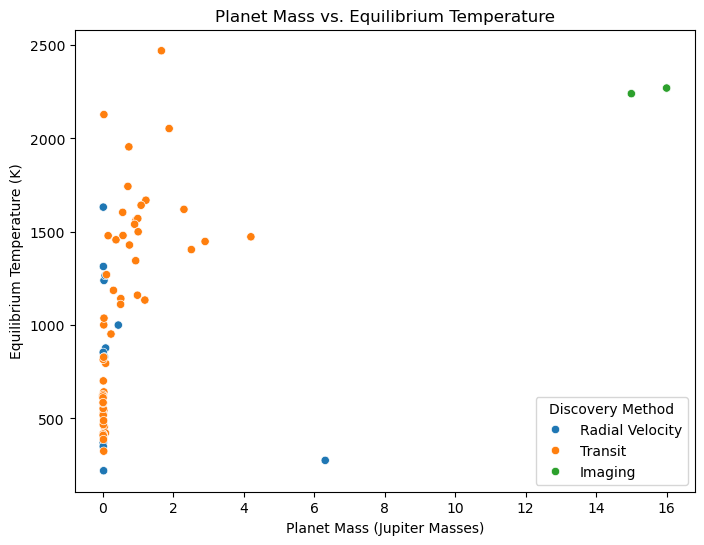

In [22]:
# transit (detects through decrease in star brightness from covering) , radial velocity (measures small wobble), imaging(capturing actual light). transit has the most, imaging has the least. 
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data = small_df,
    x='pl_bmassj',
    y='pl_eqt', 
    hue='discoverymethod',
)

plt.title('Planet Mass vs. Equilibrium Temperature')
plt.xlabel('Planet Mass (Jupiter Masses)')
plt.ylabel('Equilibrium Temperature (K)')
plt.legend(title='Discovery Method')

plt.show()

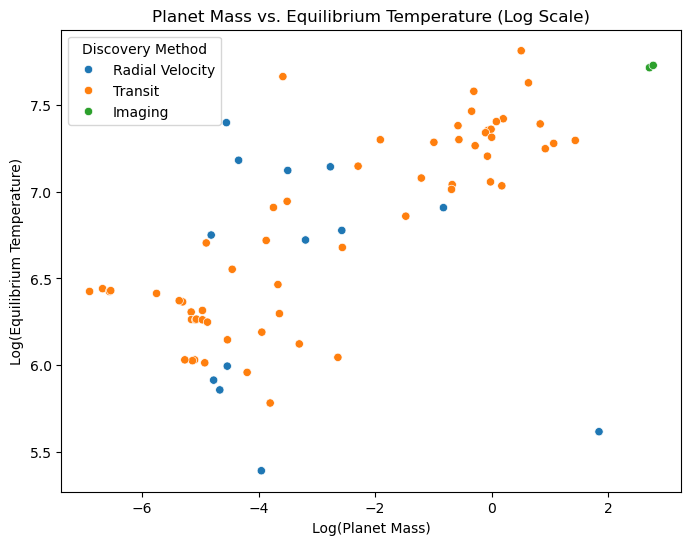

In [23]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=small_df,
    x=np.log(small_df['pl_bmassj']),
    y=np.log(small_df['pl_eqt']),
    hue='discoverymethod'
)

plt.title('Planet Mass vs. Equilibrium Temperature (Log Scale)')
plt.xlabel('Log(Planet Mass)')
plt.ylabel('Log(Equilibrium Temperature)')
plt.legend(title='Discovery Method')

plt.show()

In [25]:
# imaged exoplanets are more likely to be massive. 


In [26]:
mass_filter = small_df[small_df['pl_bmassj'] > 5]

coldest_planet = mass_filter.loc[mass_filter['pl_eqt'].idxmin()]

print(coldest_planet)

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 593, dtype: object


In [30]:
print(coldest_planet.name) # index

593


In [33]:
print(coldest_planet['pl_eqt'], "K")

275.0 K


In [34]:
print(coldest_planet['pl_bmassj'])

6.31


In [36]:
print(coldest_planet['st_spectype']) # its a K type so its cooler than the sun 

K5 V


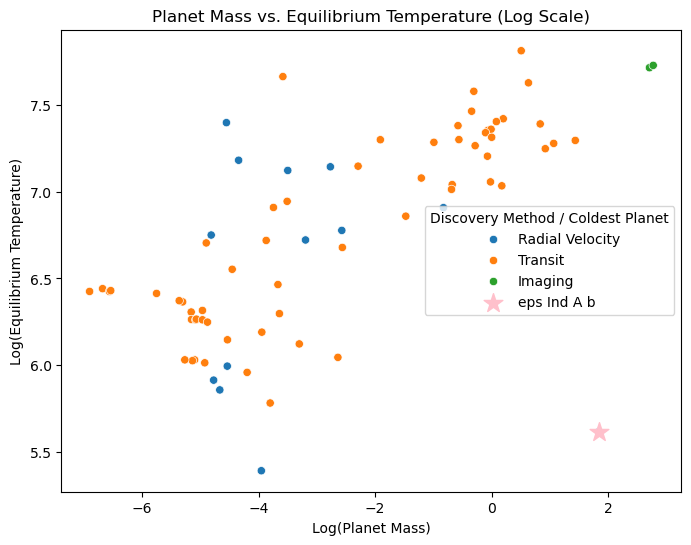

In [37]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=small_df,
    x=np.log(small_df['pl_bmassj']),
    y=np.log(small_df['pl_eqt']),
    hue='discoverymethod'
)

plt.scatter(
    np.log(coldest_planet['pl_bmassj']),
    np.log(coldest_planet['pl_eqt']),
    color = 'pink',
    marker='*',
    s=200,
    label=coldest_planet['pl_name']
)


plt.title('Planet Mass vs. Equilibrium Temperature (Log Scale)')
plt.xlabel('Log(Planet Mass)')
plt.ylabel('Log(Equilibrium Temperature)')
plt.legend(title='Discovery Method / Coldest Planet')

plt.show()

In [38]:
# The title is "A temperate super-Jupiter imaged with JWST in the mid-infrared" 
# They found a new exoplanet that is bright and cold and the only planet in the system and it's not what was predicted 
# Yes it matches
# the exoplanet is very massive but cold
# yes it shows how there can be a planet that is both very large and very cold. 